<center>

# NEISS Injury Narratives

### Break Through Tech AI Studio · Marsh McLennan 1A

</center>

<center>

Milestone #1

</center>

In [1]:
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 100
pd.set_option("display.max_colwidth", 140)
colors = sns.color_palette("tab10")

<center>

## Loading the Data

</center>

In [2]:
df = pd.read_csv("../data/neiss2025 1(NEISS_2025).csv")
print("NEISS shape:", df.shape)
df.head()

NEISS shape: (410201, 25)


,CPSC_Case_Number,Treatment_Date,Age,Sex,Race,Other_Race,Hispanic,Body_Part,Diagnosis,Other_Diagnosis,...,Fire_Involvement,Product_1,Product_2,Product_3,Alcohol,Drug,Narrative_1,Stratum,PSU,Weight
0,250102066,1/1/2025,47,2,2,NaN,2,36,59,NaN,...,0,4076,1807,0,0,0,47YOF C/O RIGHT LEG LACERATION. WAS GETTING INTO BED THIS EVENING AND TRIPPED HITTING HER LEFT LEG CONDITIONER THAT WAS ON THE FLOOR. ...,M,200,46.4246
1,250102073,1/1/2025,64,1,1,NaN,2,37,64,NaN,...,0,1842,1829,0,0,0,64YOM C/O ANKLE PAIN AND RIGHT WRIST PAIN AFTER MISSING 2 STEPS AND INVERTING HIS ANKLE. HIT RIGHT HAND ON A RAILING AT THE TIME. SCAN...,M,200,46.4246
2,250102084,1/1/2025,56,1,4,NaN,2,75,62,NaN,...,0,466,4056,0,0,0,56YOM C/O HEAD INJURY. LARGE POT FELL OFF A SHELF YESTERDAY AND HIT HIM IN THE HEAD CAUSING HIM TO FALL TO THE GROUND. ABRASION NOTED ...,M,200,46.4246
3,250102089,1/1/2025,73,1,1,NaN,2,76,59,NaN,...,0,4057,0,0,0,0,"73YOM C/O FALL AND LACERATION. TRIPPED OVER HIS FEET WHICH CAUSED HIM TO HIT HIS FOREHEAD ON THE TABLE. DX: FACIAL LACERATION, FALL",M,200,46.4246
4,250102091,1/1/2025,87,1,1,NaN,2,30,71,PAIN,...,0,676,0,0,0,0,87YOM C/O FALL ON BATHMAT. LEFT SHOULDER PAIN NOTED. DX: FALL,M,200,46.4246


In [3]:
#Product_1 is a number, so pull the product names from the codebook sheet
fmt = pd.read_csv("../data/neiss2025 1(NEISS_FMT).csv")
fmt.columns = ['format', 'code', 'end', 'label']
fmt = fmt[fmt['format'].str.strip() == 'PROD']

#Labels look like "101 - WASHING MACHINES", keep just the name
prod_names = dict(zip(fmt['code'].astype(int), fmt['label'].str.replace(r'^\d+ - ', '', regex=True)))
df['product'] = df['Product_1'].map(prod_names)

print("Product codes defined:", len(prod_names))

Product codes defined: 1124


<center>

## Narrative Structure

`Narrative_1` is the only substantial free-text field, so it is our **only
feature**: the Marsh test set is raw workers' comp descriptions with no NEISS codes attached.

</center>

In [4]:
narr = df['Narrative_1'].fillna('')
n_chars = narr.str.len()
n_words = narr.str.split().str.len()

print("Empty narratives:", (n_chars == 0).sum())
pd.DataFrame({'characters': n_chars.describe(), 'words': n_words.describe()}).round(1)

Empty narratives: 0


,characters,words
count,410201.0,410201.0
mean,130.8,23.6
std,67.0,11.8
min,24.0,3.0
25%,82.0,15.0
50%,114.0,21.0
75%,163.0,29.0
max,400.0,83.0


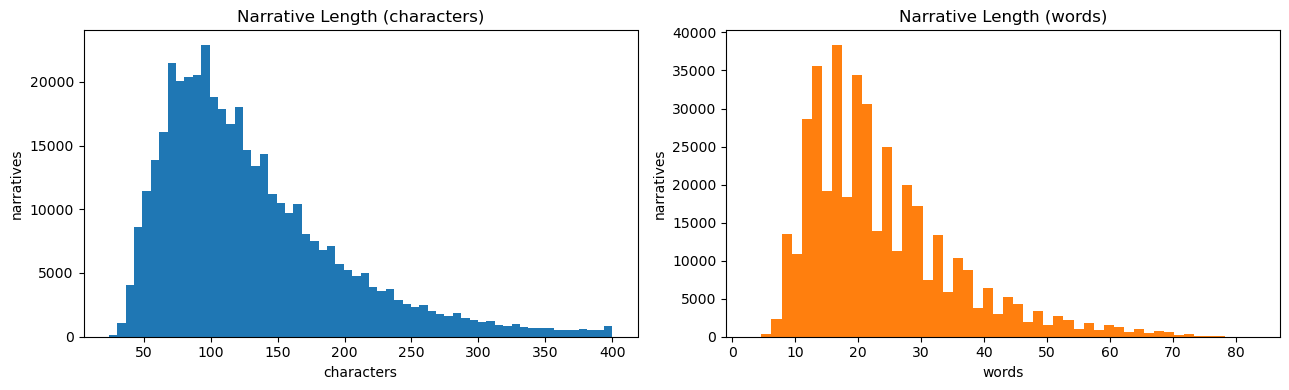

In [5]:
#Narrative length
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(n_chars, bins=60, color=colors[0])
axes[0].set_title('Narrative Length (characters)')
axes[0].set_xlabel('characters')
axes[0].set_ylabel('narratives')

axes[1].hist(n_words, bins=50, color=colors[1])
axes[1].set_title('Narrative Length (words)')
axes[1].set_xlabel('words')
axes[1].set_ylabel('narratives')

plt.tight_layout()
plt.show()

In [6]:
#Read a random sample
for t in narr[n_chars > 0].sample(8, random_state=SEED):
    print(t, '\n')

59 YOF FELL DOWN THE STAIRS 1 WEEK AGO AND HAS NOT BEEN TREATED. DX: FRACTURE OF RIGHT CLAVICLE 

91YOF WAS GOING ON HER DAILY WALK WITH HER WALKER WHEN SUDDENLY IT SLIPPED AND SHE FELL TO LEFT SIDE, HITTING SHOULDER AND RIGHT SIDE OF HEAD. DX: LACERATION OF SCALP; CLOSED DISPLACED FRACTURE OF ACROMIAL END OF LEFT CLAVICLE 

3YOM WAS JUMPING ON TRAMPOLINE WITH BROTHER WHEN PT FELL ONTO HIS RIGHT ARM DX: FRACTURE OF RIGHT HUMERUS 

30 YOF SMASHED HER FINGER IN A DOOR. DX: RIGHT THUMB CONTUSION 

13YOF WAS THE UNRESTRAINED PASSENGER ON A SIDE BY SIDE ATV AND IT FLIPPED OVER WHILE GOING AROUND A CORNER DX STRAINED RIGHT ANKLE 

15MOF WAS PLAYING WITH POTS AND PANS WHEN SHE INJURED RIGHT 5TH FINGER. DX: SUBUNGUAL HEMATOMA OF FINGER. 

80 YOM PRESENTS EMERGENCY DEPARTMENT TODAY AFTER A FALL.  PATIENT STATES HE WAS AT THE GROCERY STORE, LOST HIS BALANCE AND FELL BACKWARDS DOWN THE STAIRS.  HE DID STRIKE HIS HEAD, DID NOT LOSE CONSCIOUSNESS. DX CLOSED HEAD INJURY 

80YOF PRESENTS WITH HEAD PA

In [7]:
#Clinical shorthand frequency, the work list for normalization
patterns = {
    'age+sex (47YOF)':  r"\b\d{1,3}\s*Y[O/]?\s*[MF]\b",
    'C/O':              r"\bC/O\b",
    'DX:':              r"\bDX\b",
    'S/P':              r"\bS/P\b",
    'PT':               r"\bPT\b",
    'W/':               r"\bW/",
    '* (redaction)':    r"\*",
    '@':                r"@",
}

shorthand = pd.Series({k: narr.str.contains(v).mean() * 100 for k, v in patterns.items()})
shorthand.round(1).sort_values(ascending=False).rename('% of narratives')

DX:                99.9
age+sex (47YOF)    94.0
PT                 11.1
C/O                 9.6
S/P                 4.5
* (redaction)       3.2
W/                  1.8
@                   0.1
Name: % of narratives, dtype: float64

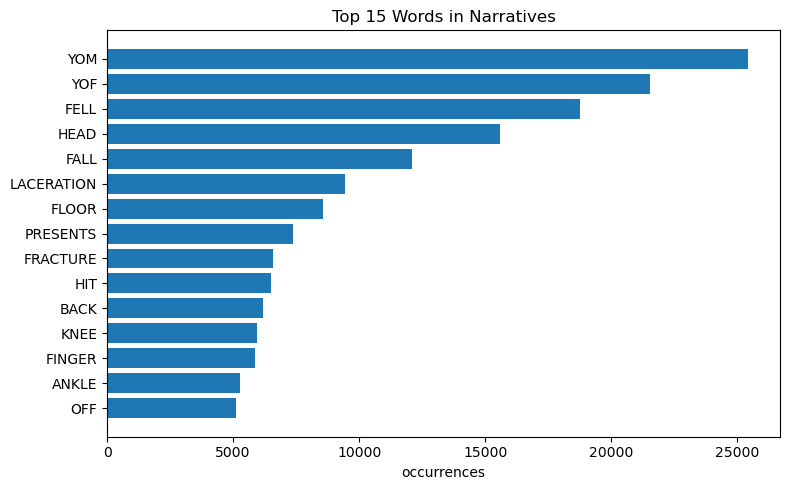

In [8]:
#Most common words, ignoring filler
filler = {'THE','AND','WAS','WERE','HIS','HER','SHE','WITH','FOR','FROM','AFTER','WHILE','HAD',
          'INTO','OUT','THEN','WHEN','THIS','THAT','NOT','PATIENT','LEFT','RIGHT','PAIN',
          'INJURY','CLOSED','NOTED','STATES','PER','HOME','TODAY'}

words = Counter()
for t in narr.sample(50_000, random_state=SEED):
    words.update(w for w in re.findall(r"[A-Z]{3,}", t.upper()) if w not in filler)

top = pd.DataFrame(words.most_common(15), columns=['word', 'count'])

plt.figure(figsize=(8, 5))
plt.barh(top['word'][::-1], top['count'][::-1], color=colors[0])
plt.title('Top 15 Words in Narratives')
plt.xlabel('occurrences')
plt.tight_layout()
plt.show()

<center>

## Feature Candidates

</center>

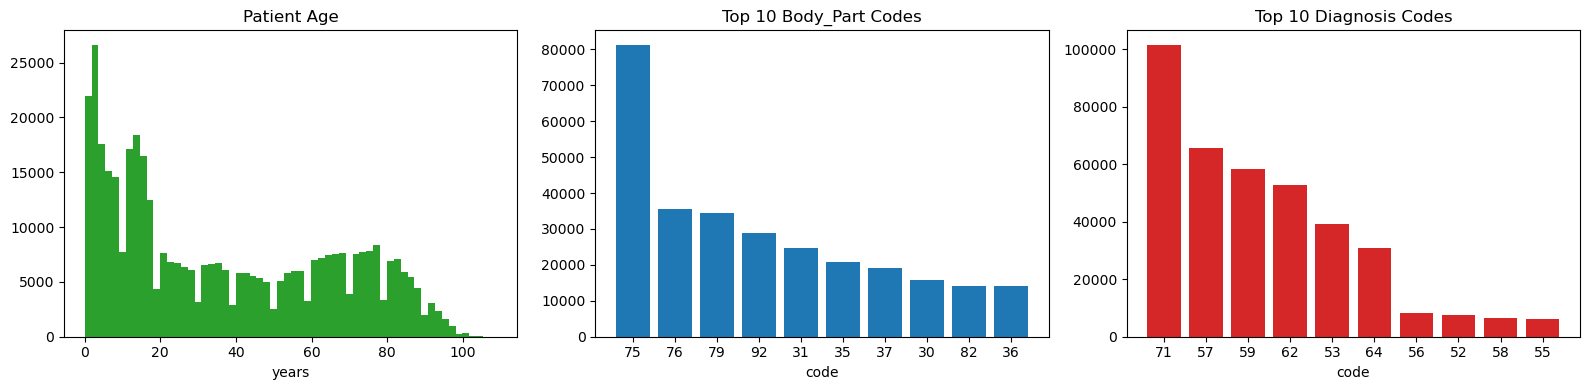

In [9]:
#Age, body part, diagnosis
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

#Ages above 200 are babies counted in months (201 = 1 month), so convert to years
age = df['Age'].where(df['Age'] <= 120, (df['Age'] - 200) / 12)
axes[0].hist(age, bins=60, color=colors[2])
axes[0].set_title('Patient Age')
axes[0].set_xlabel('years')

for ax, col, c in [(axes[1], 'Body_Part', colors[0]), (axes[2], 'Diagnosis', colors[3])]:
    top = df[col].value_counts().head(10)
    ax.bar(top.index.astype(str), top.values, color=c)
    ax.set_title(f'Top 10 {col} Codes')
    ax.set_xlabel('code')

plt.tight_layout()
plt.show()

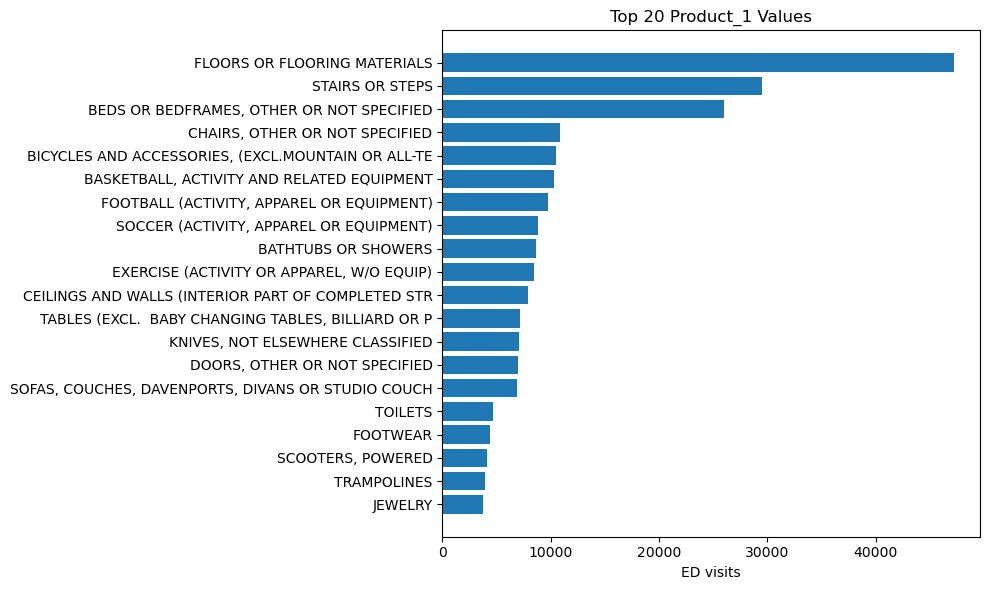

In [10]:
#Top products, our label
top_prod = df['product'].value_counts().head(20)

plt.figure(figsize=(10, 6))
plt.barh(top_prod.index.str[:50][::-1], top_prod.values[::-1], color=colors[0])
plt.title('Top 20 Product_1 Values')
plt.xlabel('ED visits')
plt.tight_layout()
plt.show()

<center>

### Column decisions

| Decision | Columns | Reason |
|---|---|---|
| **Feature** | `Narrative_1` | The only input available at inference |
| **Label** | `Product_1` | The object the NEISS coder recorded |
| **Future use** | `Age`, `Body_Part`, `Diagnosis`, `Disposition`, `Fire_Involvement`, `Alcohol`, `Drug` | Not available at inference, but useful for later severity work |
| **Eliminate** | `CPSC_Case_Number`, `Treatment_Date`, `Race`, `Other_Race`, `Hispanic`, `Sex`, `PSU`, `Weight`, `Stratum` | IDs, survey design, or protected characteristics |
| **Undecided** | `Location`, `Product_2`, `Product_3` | Revisit once the base case works |

`PSU` is dropped as a feature but kept for **splitting**: it identifies the hospital, and
narrative style varies by hospital.

</center>

<center>

## Task #4: The Label

**Label = `Product_1`, feature = `Narrative_1`.**

</center>

In [ ]:
#How concentrated are the products? (0 means no product)
counts = df.loc[df['Product_1'] != 0, 'product'].value_counts()
coverage = counts.cumsum() / counts.sum()

print("Product classes in use:", len(counts))
for n in [10, 25, 50, 100, 200]:
    print(f"top {n:>3} classes cover {coverage.iloc[n-1]*100:.1f}% of rows")

rare = counts[counts < 100]
print(f"\nClasses with <100 examples: {len(rare)} ({rare.sum()/counts.sum()*100:.1f}% of rows)")

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(coverage) + 1), coverage.values * 100, color=colors[0])
plt.xscale('log')
plt.title('Product_1 Cumulative Coverage')
plt.xlabel('classes, ranked by frequency (log scale)')
plt.ylabel('% of rows covered')
plt.tight_layout()
plt.show()

In [23]:
#Vague labels teach the model very little
vague = df['product'].str.contains('NOT SPECIFIED|NOT ELSEWHERE|UNSPECIFIED|N.E.C|MISCELLANEOUS',
                                   na=False)

print(f"Rows with a vague Product_1: {vague.sum():,} ({vague.mean()*100:.1f}%)")
df.loc[vague, 'product'].value_counts().head(8)

Rows with a vague Product_1: 91,260 (22.2%)


product
BEDS OR BEDFRAMES, OTHER OR NOT SPECIFIED    25989
CHAIRS, OTHER OR NOT SPECIFIED               10818
KNIVES, NOT ELSEWHERE CLASSIFIED              7034
DOORS, OTHER OR NOT SPECIFIED                 6949
LADDERS, OTHER OR NOT SPECIFIED               3327
SCOOTERS, UNSPECIFIED                         3036
CONTAINERS, NOT SPECIFIED                     2710
RUGS OR CARPETS, NOT SPECIFIED                2541
Name: count, dtype: int64

<center>

### Does the label appear in the text?

`Product_1` is assigned by the coder, not necessarily a word in the narrative. How often the
product name is literally present tells us how learnable the mapping is.

</center>

In [13]:
#Does any word of the product name show up in the narrative?
skip = {'OTHER','NOT','SPECIFIED','ELSEWHERE','CLASSIFIED','AND','THE','WITH','FOR',
        'EQUIPMENT','RELATED','TYPE','TYPES','USED','PARTS','PART'}

sample = df[(df['Product_1'] != 0) & (n_chars > 0)].sample(20_000, random_state=SEED)

found = []
for text, label in zip(sample['Narrative_1'], sample['product']):
    label_words = set(re.findall(r"[A-Z]{4,}", re.sub(r"\(.*?\)", "", label.upper()))) - skip
    text_words = set(re.findall(r"[A-Z]{4,}", text.upper()))
    #Strip a trailing S so LADDERS matches LADDER
    found.append(any(w.rstrip('S') in {t.rstrip('S') for t in text_words} for w in label_words))

sample['in_text'] = found
print(f"Product name appears in narrative: {sample['in_text'].mean()*100:.1f}%")
print(f"Excluding vague labels: {sample.loc[~vague[sample.index], 'in_text'].mean()*100:.1f}%")

Product name appears in narrative: 66.3%
Excluding vague labels: 72.1%


<center>

## Task #5: Missing Values and Outliers

NEISS has **no true missing data**: blanks are conditional fields and the real missingness is
coded as a sentinel value, so we drop almost nothing.

</center>

In [16]:
#True blanks
blanks = df.isna().sum()
blanks[blanks > 0]

Other_Race           395149
Other_Diagnosis      308997
Body_Part_2          313426
Diagnosis_2          313426
Other_Diagnosis_2    383193
dtype: int64

In [17]:
#The Other_* text is only filled in when its code says OTHER, so those blanks are expected
print("Other_Diagnosis mismatches:", (df['Other_Diagnosis'].notna() != (df['Diagnosis'] == 71)).sum(),
      "(the rest come from Diagnosis_2)")
print("Other_Race mismatches:", (df['Other_Race'].notna() != (df['Race'] == 3)).sum())

Other_Diagnosis mismatches: 276 (the rest come from Diagnosis_2)
Other_Race mismatches: 0


In [18]:
#The real missingness is coded: these look like normal categories
sentinels = {'Location': 0, 'Diagnosis': 71, 'Body_Part': 87, 'Fire_Involvement': 0,
             'Alcohol': 0, 'Drug': 0}

pd.Series({f"{c} = {k}": (df[c] == k).mean() * 100 for c, k in sentinels.items()}).round(1)

Location = 0            35.9
Diagnosis = 71          24.7
Body_Part = 87           3.3
Fire_Involvement = 0    99.5
Alcohol = 0             98.1
Drug = 0                98.1
dtype: float64

In [19]:
#Outliers in the feature: narrative length
cap = n_chars.max()
print(f"median {n_chars.median():.0f} | max {cap}")
print("truncated at the cap:", (n_chars == cap).sum())
print("under 40 characters :", (n_chars < 40).sum())

print("\nshortest:")
print(narr[n_chars > 0].loc[n_chars[n_chars > 0].sort_values().index[:3]].to_string())

median 114 | max 400
truncated at the cap: 168
under 40 characters : 3016

shortest:
250823     2 YOM *** IN NOSE DX: FB
234224    7MOM FELL OFF BED. DX CHI
281686    6MOM FELL OFF BED. DX CHI


In [20]:
#Duplicate narratives are short formulaic cases, not errors
dup = narr.duplicated(keep=False) & (n_chars > 0)

print("rows with a non-unique narrative:", dup.sum())
narr[dup].value_counts().head(5)

rows with a non-unique narrative: 1861


Narrative_1
14YOM TWISTED ANKLE PLAYING BASKETBALL.  DX: ANKLE SPRAIN    16
15YOM TWISTED ANKLE PLAYING BASKETBALL.  DX: ANKLE SPRAIN    16
17YOM TWISTED ANKLE PLAYING BASKETBALL.  DX: ANKLE SPRAIN    14
16YOM TWISTED ANKLE PLAYING BASKETBALL.  DX: ANKLE SPRAIN    13
2YOM FELL DOWN STEPS.  DX: HEAD INJURY                       10
Name: count, dtype: int64

<center>

### Cleaning decisions

| Finding | Decision | Why |
|---|---|---|
| Blank `Other_*`, `Body_Part_2`, `Diagnosis_2` | **Keep all rows** | Conditional fields, not data loss |
| Sentinel codes (`Location=0`, `Diagnosis=71`, …) | **Recode to NaN** if used | Otherwise UNK ranks as a real category |
| Administrative `Product_1` codes | **Drop rows** | `NO PRODUCT` can't be a target |
| Truncated or under-40-char narratives | **Flag, keep** | Short or cut off, but still usable |
| Duplicate narrative text | **Keep, group when splitting** | Prevents train/test leakage |
| Vague `Product_1` label | **Keep, exclude from training** | Belongs in evaluation only |
| `Product_1` class with <100 examples | **Keep, flag as rare** | Too thin to learn per class |
| `Age` months encoding | **Recode** | Converted to years above |

</center>

In [21]:
#Build the cleaned frame with flags
admin = df['Product_1'].isin([0, 8888, 9999, 9000, 9001, 9002, 9003, 9100, 9200])

clean = pd.DataFrame({
    'case_number': df['CPSC_Case_Number'],
    'narrative': narr,
    'product_code': df['Product_1'],
    'product_label': df['product'],
    'truncated': n_chars == cap,
    'short': n_chars < 40,
    'vague_label': vague,
    'rare_class': df['product'].isin(rare.index),
    'dup_narrative': dup,
    'psu': df['PSU'],       #not a feature, the grouping key for splits
})
clean = clean[~admin & (n_chars > 0)].reset_index(drop=True)

train_pool = clean[~clean['vague_label'] & ~clean['rare_class']]

print(f"raw: {len(df):,} | cleaned: {len(clean):,} | training pool: {len(train_pool):,}")

raw: 410,201 | cleaned: 410,201 | training pool: 308,257


<center>

## Results and Analysis

</center>

In [22]:
pd.DataFrame({
    'Rows in raw dataset': len(df),
    'Rows after cleaning': len(clean),
    'Median narrative length (chars)': int(n_chars.median()),
    'Product_1 classes in use': len(counts),
    'Classes covering 90% of rows': int((coverage < 0.90).sum()) + 1,
    'Vague product labels (%)': round(vague.mean() * 100, 1),
    'Product name in narrative (%)': round(sample['in_text'].mean() * 100, 1),
    'Training pool rows': len(train_pool),
}, index=['value']).T

,value
Rows in raw dataset,410201.0
Rows after cleaning,410201.0
Median narrative length (chars),114.0
Product_1 classes in use,767.0
Classes covering 90% of rows,157.0
Vague product labels (%),22.2
Product name in narrative (%),66.3
Training pool rows,308257.0
